# Laboratorio 07: precio de viviendas con regresión lineal
**Objetivo:** explorar los datos, aplicar regresión lineal y preparar un archivo para Kaggle.

Usaremos tablas sencillas, histogramas y gráficos de dispersión. El único algoritmo será `LinearRegression`. Primero veremos una regresión simple con superficie; después una múltiple con algunas características. Si el profesor exige una sola variable, podemos entregar el archivo simple.

En Kaggle se busca un error pequeño, no llegar obligatoriamente a 0. El resultado local no es el score del leaderboard.

## 1. Importar librerías
Pandas permite leer y preparar tablas; NumPy aplica logaritmos; matplotlib dibuja los gráficos; scikit-learn entrena y evalúa la regresión. Ejecuta las celdas de arriba hacia abajo con el entorno `lab02_alca`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 12)

## 2. Leer los archivos
`train.csv` tiene precios conocidos. `test.csv` contiene las viviendas que debemos predecir. `Id` identifica cada vivienda y no se utiliza para entrenar. La carpeta de trabajo debe ser `lab07_alca`.

In [2]:
datos = Path("house-prices-advanced-regression-techniques")
salida = Path("outputs")
salida.mkdir(exist_ok=True)

train = pd.read_csv(datos / "train.csv")
test = pd.read_csv(datos / "test.csv")
ejemplo = pd.read_csv(datos / "sample_submission.csv")
print("Entrenamiento:", train.shape)
print("Datos para Kaggle:", test.shape)
print("Duplicados:", train.duplicated().sum())
train.head()

Entrenamiento: (1460, 81)
Datos para Kaggle: (1459, 80)
Duplicados: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,...,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,...,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,...,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,...,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,...,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,...,0,12,2008,WD,Normal,250000


## 3. Separar entrenamiento y validación
Reservamos 20% de `train.csv` para comprobar predicciones sobre precios conocidos. Exploramos el 80% restante. `test.csv` no sirve para evaluar localmente porque no tiene precios reales. La semilla 42 permite repetir la misma división.

In [3]:
entrenamiento, validacion = train_test_split(train, test_size=0.20, random_state=42)
print("Entrenamiento local:", len(entrenamiento))
print("Validación local:", len(validacion))
entrenamiento[["SalePrice", "GrLivArea", "OverallQual", "GarageCars"]].describe()

Entrenamiento local: 1168
Validación local: 292


,SalePrice,GrLivArea,OverallQual,GarageCars
count,1168.000000,1168.000000,1168.000000,1168.000000
mean,181441.541952,1527.401541,6.121575,1.781678
std,77263.583862,524.432686,1.367619,0.740161
min,34900.000000,334.000000,1.000000,0.000000
25%,130000.000000,1145.750000,5.000000,1.000000
50%,165000.000000,1473.000000,6.000000,2.000000
75%,214925.000000,1792.000000,7.000000,2.000000
max,745000.000000,5642.000000,10.000000,4.000000


## 4. EDA: faltantes y precios
Revisamos cuántos valores faltan. Un faltante puede significar ausencia de una instalación; el diccionario `data_description.txt` permite comprobarlo. No eliminaremos viviendas automáticamente.

El histograma muestra cuántas viviendas hay en cada rango de precio. Las viviendas más caras generan una cola hacia la derecha.

PoolQC          1162
MiscFeature     1122
Alley           1094
Fence            935
MasVnrType       683
FireplaceQu      547
LotFrontage      217
GarageQual        64
GarageFinish      64
GarageType        64
GarageYrBlt       64
GarageCond        64
BsmtCond          28
BsmtQual          28
BsmtExposure      28
dtype: int64


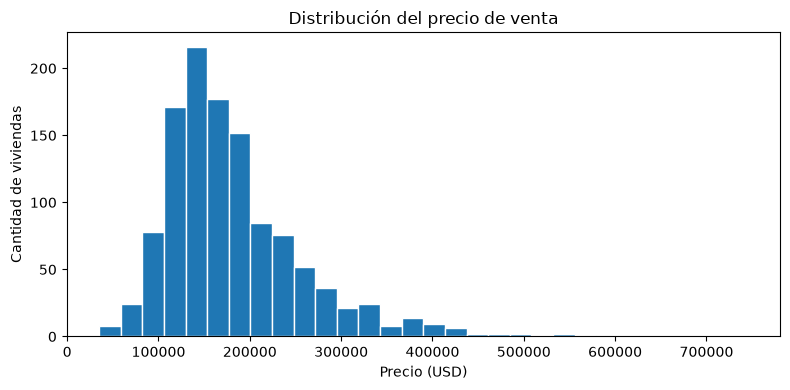

In [4]:
faltantes = entrenamiento.isna().sum().sort_values(ascending=False)
print(faltantes[faltantes > 0].head(15))

plt.figure(figsize=(8, 4))
plt.hist(entrenamiento["SalePrice"], bins=30, edgecolor="white")
plt.title("Distribución del precio de venta")
plt.xlabel("Precio (USD)")
plt.ylabel("Cantidad de viviendas")
plt.tight_layout()
plt.show()

## 5. EDA: superficie, calidad y precio
Cada punto representa una vivienda. `GrLivArea` es superficie habitable sobre el suelo, en pies cuadrados. `OverallQual` es una calificación de calidad de 1 a 10. Observamos asociaciones, no relaciones de causa y efecto. Los puntos extremos se conservan.

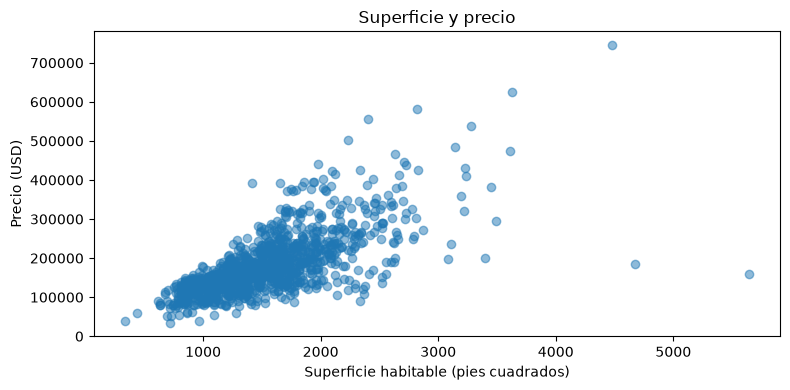

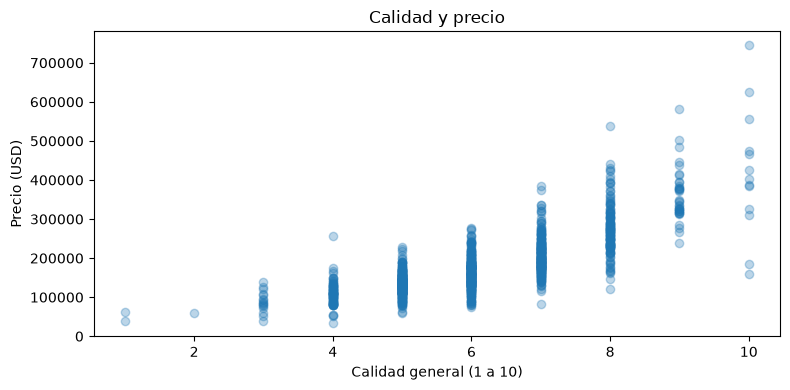

In [5]:
plt.figure(figsize=(8, 4))
plt.scatter(entrenamiento["GrLivArea"], entrenamiento["SalePrice"], alpha=0.5)
plt.title("Superficie y precio")
plt.xlabel("Superficie habitable (pies cuadrados)")
plt.ylabel("Precio (USD)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(entrenamiento["OverallQual"], entrenamiento["SalePrice"], alpha=0.3)
plt.title("Calidad y precio")
plt.xlabel("Calidad general (1 a 10)")
plt.ylabel("Precio (USD)")
plt.tight_layout()
plt.show()

**Lectura:** en general, mayor superficie y mayor calidad se asocian con precios mayores. La dispersión muestra que una sola característica no explica todos los precios. Estos gráficos relacionan **variables explicativas X** con el **precio real Y**; todavía no evaluamos predicciones.

### Pairplot: varias relaciones en una figura
`seaborn.pairplot` reúne gráficos de dispersión para cada par de variables y, en la diagonal, histogramas de cada variable. Elegimos cuatro columnas para que sea legible: precio **real**, superficie, calidad y capacidad del garaje. `Id` no aporta una característica de la vivienda y no lo incluimos.

Se utiliza solo el conjunto de entrenamiento local. Lee las etiquetas de cada fila/columna: en los cruces con `SalePrice` observamos asociaciones con el precio; en los demás, asociaciones entre características. No son predicciones ni pruebas de causalidad. El pairplot ayuda al EDA, pero por sí solo no mejora el score.

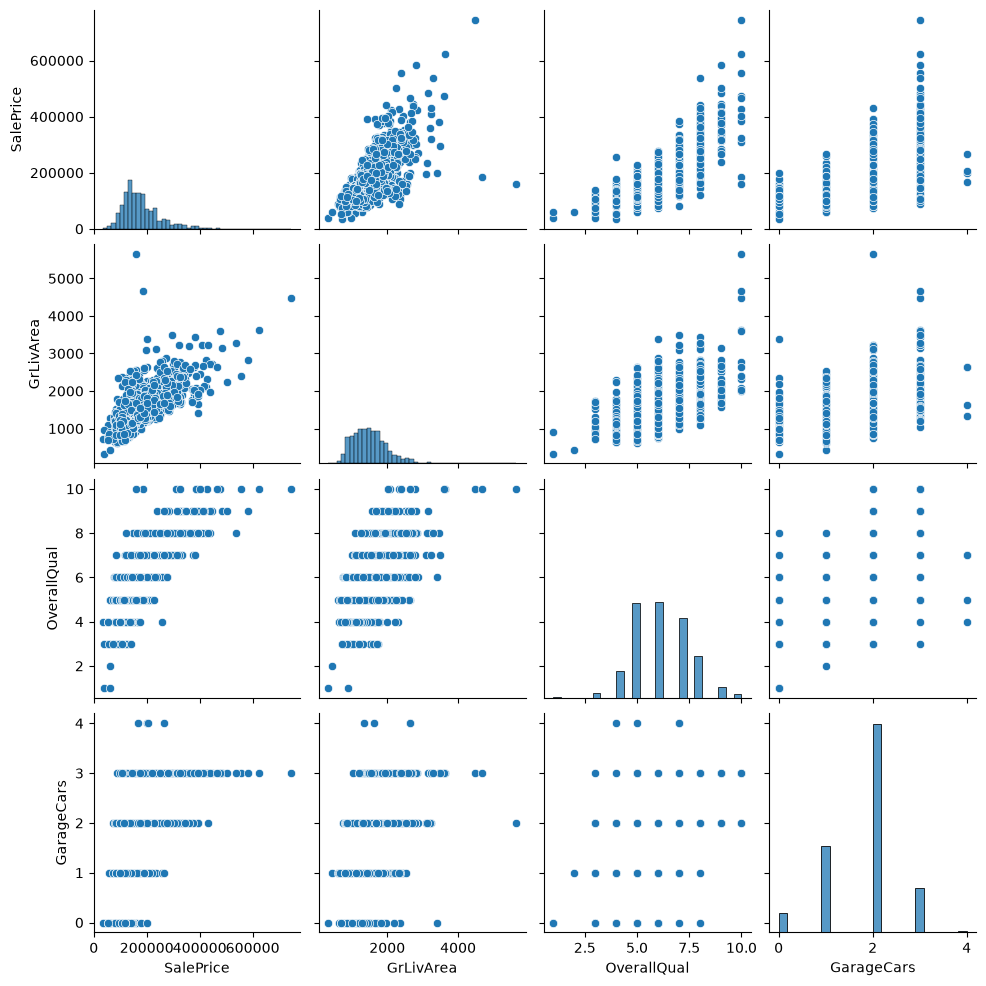

In [6]:
variables_eda = ["SalePrice", "GrLivArea", "OverallQual", "GarageCars"]
sns.pairplot(entrenamiento[variables_eda], diag_kind="hist")
plt.show()

## 6. Regresión simple: una variable, como en clase
`precio estimado = intercepto + pendiente × superficie`.

`fit` estima la recta por mínimos cuadrados. La pendiente indica el cambio asociado en USD por un pie cuadrado adicional. El intercepto corresponde a superficie cero, fuera del rango práctico: no es el precio real de una vivienda.

Intercepto: 24899.75
Pendiente: 102.49
R² en entrenamiento: 0.4839


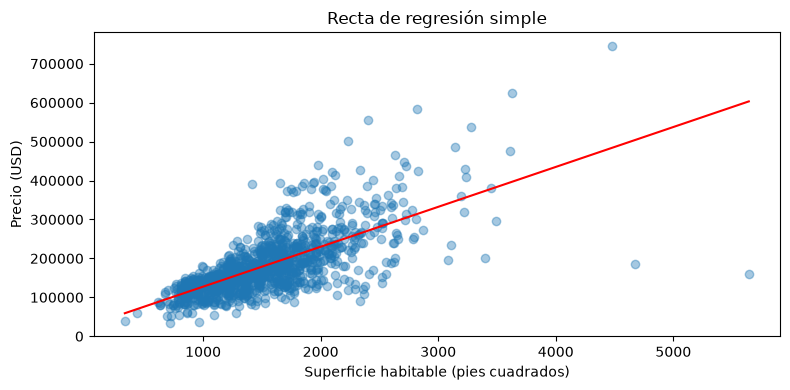

In [7]:
simple = LinearRegression()
simple.fit(entrenamiento[["GrLivArea"]], entrenamiento["SalePrice"])

print("Intercepto:", round(simple.intercept_, 2))
print("Pendiente:", round(simple.coef_[0], 2))
print("R² en entrenamiento:", round(simple.score(entrenamiento[["GrLivArea"]], entrenamiento["SalePrice"]), 4))

superficies = entrenamiento[["GrLivArea"]].sort_values("GrLivArea")
plt.figure(figsize=(8, 4))
plt.scatter(entrenamiento["GrLivArea"], entrenamiento["SalePrice"], alpha=0.4)
plt.plot(superficies["GrLivArea"], simple.predict(superficies), color="red")
plt.title("Recta de regresión simple")
plt.xlabel("Superficie habitable (pies cuadrados)")
plt.ylabel("Precio (USD)")
plt.tight_layout()
plt.show()

## 7. Preparar una regresión múltiple con pasos directos
Seguimos usando **el mismo algoritmo**, ahora con varias características. Seleccionamos calidad, superficie, garaje, antigüedad aproximada por años, baños, chimeneas, barrio y calidad de cocina/exterior. No utilizamos todas las columnas.

- Los números faltantes se completan con la **mediana del entrenamiento**.
- El texto faltante se reemplaza por `SinDato` como simplificación.
- `get_dummies` convierte textos en columnas de 0 y 1. En entrenamiento omitimos una categoría de referencia; validación conserva solo las columnas aprendidas. Una categoría nueva queda codificada como referencia, una limitación.
- Aplicamos `log` al precio y `log1p` a la superficie para reducir valores extremos. Seguimos haciendo regresión lineal sobre el logaritmo del precio; no es regresión logística.

No usamos pipelines, transformadores, búsqueda de parámetros ni validación cruzada.

In [8]:
numericas = ["OverallQual", "OverallCond", "GrLivArea", "GarageCars", "YearBuilt",
             "YearRemodAdd", "FullBath", "HalfBath", "Fireplaces"]
categoricas = ["Neighborhood", "KitchenQual", "ExterQual"]
columnas = numericas + categoricas

X_train = entrenamiento[columnas].copy()
X_val = validacion[columnas].copy()

medianas = X_train[numericas].median()
X_train[numericas] = X_train[numericas].fillna(medianas)
X_val[numericas] = X_val[numericas].fillna(medianas)
X_train[categoricas] = X_train[categoricas].fillna("SinDato")
X_val[categoricas] = X_val[categoricas].fillna("SinDato")

X_train["GrLivArea"] = np.log1p(X_train["GrLivArea"])
X_val["GrLivArea"] = np.log1p(X_val["GrLivArea"])
X_train = pd.get_dummies(X_train, columns=categoricas, drop_first=True, dtype=int)
X_val = pd.get_dummies(X_val, columns=categoricas, dtype=int)
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)

y_train = np.log(entrenamiento["SalePrice"])
print("Columnas después de convertir textos:", X_train.shape[1])
X_train.head()

Columnas después de convertir textos: 39


,OverallQual,OverallCond,GrLivArea,GarageCars,YearBuilt,YearRemodAdd,...,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA,ExterQual_Fa,ExterQual_Gd,ExterQual_TA
254,5,6,7.181592,1,1957,1957,...,0,0,1,0,0,1
1066,6,7,7.360104,2,1993,1994,...,0,0,1,0,1,0
638,5,7,6.680855,0,1910,1950,...,0,0,1,0,0,1
799,5,7,7.478170,1,1937,1950,...,0,1,0,0,0,1
380,5,6,7.433667,1,1924,1950,...,0,1,0,0,0,1


## 8. Entrenar y evaluar
`predict` devuelve logaritmos; `exp` los convierte nuevamente en USD.

**MAE:** error absoluto promedio en dólares. **RMSE:** error en dólares que penaliza más las diferencias grandes. **R²:** comparación con predecir la media; no es porcentaje de aciertos. **RMSE log:** error entre logaritmos; corresponde a la métrica de Kaggle y cuanto menor, mejor.

Usamos esta división una vez para evaluar; no buscamos parámetros repetidamente sobre validación.

In [9]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)
predicciones = np.exp(modelo.predict(X_val))
precios_reales = validacion["SalePrice"]

mae = mean_absolute_error(precios_reales, predicciones)
rmse = np.sqrt(mean_squared_error(precios_reales, predicciones))
r2 = r2_score(precios_reales, predicciones)
rmse_log = np.sqrt(mean_squared_error(np.log(precios_reales), np.log(predicciones)))

print(f"MAE: {mae:,.2f} USD")
print(f"RMSE: {rmse:,.2f} USD")
print(f"R²: {r2:.4f}")
print(f"RMSE log: {rmse_log:.5f}")

pred_simple = simple.predict(validacion[["GrLivArea"]])
print("Precios simples no positivos:", int((pred_simple <= 0).sum()))
pred_simple = np.maximum(pred_simple, 1)
error_simple = np.sqrt(mean_squared_error(np.log(precios_reales), np.log(pred_simple)))
print(f"RMSE log de la regresión simple: {error_simple:.5f}")

resultados = pd.DataFrame({
    "Modelo": ["Simple", "Multiple"],
    "MAE USD": [mean_absolute_error(precios_reales, pred_simple), mae],
    "RMSE USD": [np.sqrt(mean_squared_error(precios_reales, pred_simple)), rmse],
    "R2": [r2_score(precios_reales, pred_simple), r2],
    "RMSE log": [error_simple, rmse_log]
})
resultados.to_csv(salida / "metricas_validacion.csv", index=False)
resultados

MAE: 18,301.37 USD
RMSE: 30,063.13 USD
R²: 0.8822
RMSE log: 0.14767
Precios simples no positivos: 0
RMSE log de la regresión simple: 0.28751


,Modelo,MAE USD,RMSE USD,R2,RMSE log
0,Simple,38341.204476,58471.756526,0.554263,0.287506
1,Multiple,18301.371627,30063.130363,0.882170,0.147670


## 9. Comparar precios reales y predichos
Este gráfico es una **evaluación sobre validación**, no una relación entre dos variables explicativas. El eje horizontal contiene `SalePrice` real y el vertical la predicción del modelo para esas mismas viviendas. La línea roja `predicho = real` representa coincidencia perfecta; no es una recta ajustada a estos puntos.

Un punto bajo la línea indica que el modelo subestima; uno por encima indica sobreestimación. En las viviendas caras se observan varias subestimaciones. La comparación es válida porque reservamos precios reales en validación. No podríamos hacerla con `test.csv`, cuyos precios reales desconocemos.

Para mostrar la relación explicativa que se estudia en clase, usamos **superficie frente a precio real y la recta** en la sección 6. Para evaluar errores, agregamos residuos abajo. No confundimos estas tres finalidades.

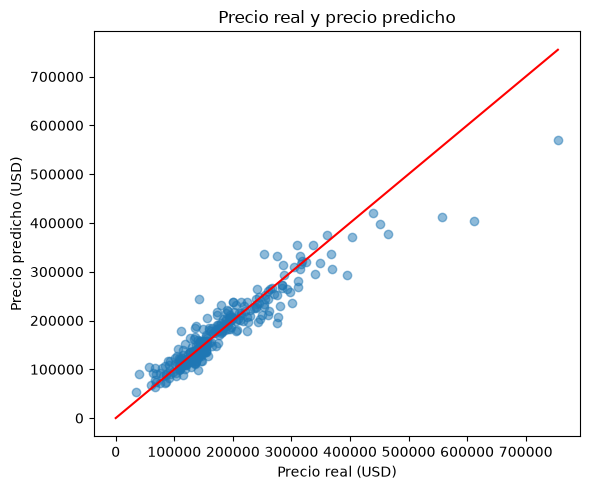

,Real,Predicho
892,154500,148755.164370
1105,325000,320557.284670
413,115000,110611.385611
522,159000,183674.053464
1036,315500,306321.895699
614,75500,72634.988863
218,311500,268211.821810
1160,146000,151612.938472
649,84500,72054.885412
887,135500,129167.006637


In [10]:
plt.figure(figsize=(6, 5))
plt.scatter(precios_reales, predicciones, alpha=0.5)
limite = max(precios_reales.max(), predicciones.max())
plt.plot([0, limite], [0, limite], color="red")
plt.title("Precio real y precio predicho")
plt.xlabel("Precio real (USD)")
plt.ylabel("Precio predicho (USD)")
plt.tight_layout()
plt.show()

comparacion = pd.DataFrame({"Real": precios_reales, "Predicho": predicciones})
comparacion.head(10)

### Evaluar residuos: cuánto y en qué dirección nos equivocamos
`residuo = precio real - precio predicho`. Un residuo positivo significa subestimación; uno negativo, sobreestimación. Usamos precios predichos en el eje X y errores en USD en el eje Y. Esperamos puntos alrededor de cero, sin un patrón claro; este gráfico orienta el diagnóstico, pero no prueba todos los supuestos.

Esto agrega una forma de evaluar, sin cambiar el regresor. Una nueva variable explicativa o métrica concreta del profesor sigue pendiente de identificar.

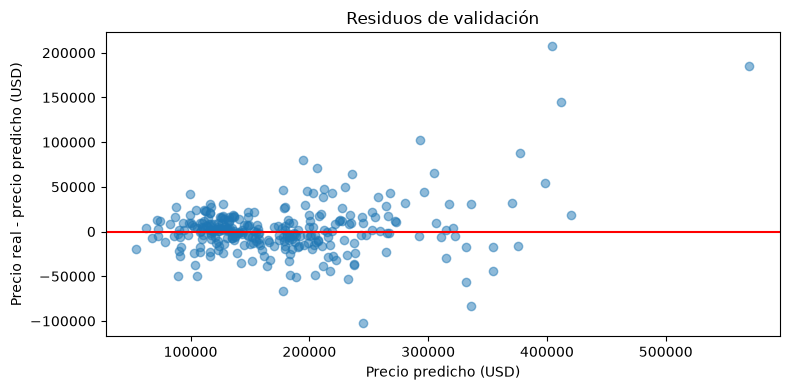

In [11]:
residuos = precios_reales - predicciones
plt.figure(figsize=(8, 4))
plt.scatter(predicciones, residuos, alpha=0.5)
plt.axhline(0, color="red")
plt.title("Residuos de validación")
plt.xlabel("Precio predicho (USD)")
plt.ylabel("Precio real - precio predicho (USD)")
plt.tight_layout()
plt.show()

## 10. Entrenar con todos los datos y crear el CSV
Terminada la evaluación, repetimos los mismos pasos con todo `train.csv`. Es código repetido intencionalmente para mostrar cada operación sin funciones auxiliares. Las medianas se calculan con `train`, nunca con `test`.

`submission.csv` usa la regresión múltiple. También generamos `submission_simple.csv` por si el profesor exige exactamente una variable. Los precios no positivos del modelo simple se ajustan a 1 USD para cumplir el formato y se reportan.

In [12]:
X = train[columnas].copy()
X_test = test[columnas].copy()

medianas_finales = X[numericas].median()
X[numericas] = X[numericas].fillna(medianas_finales)
X_test[numericas] = X_test[numericas].fillna(medianas_finales)
X[categoricas] = X[categoricas].fillna("SinDato")
X_test[categoricas] = X_test[categoricas].fillna("SinDato")

X["GrLivArea"] = np.log1p(X["GrLivArea"])
X_test["GrLivArea"] = np.log1p(X_test["GrLivArea"])
X = pd.get_dummies(X, columns=categoricas, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=categoricas, dtype=int)
X_test = X_test.reindex(columns=X.columns, fill_value=0)

modelo.fit(X, np.log(train["SalePrice"]))
precios_test = np.exp(modelo.predict(X_test))
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": precios_test})

# Comprobar el formato antes de guardar.
assert submission.columns.tolist() == ejemplo.columns.tolist()
assert len(submission) == len(test) == len(ejemplo)
assert submission["Id"].tolist() == ejemplo["Id"].tolist()
assert np.isfinite(submission["SalePrice"]).all()
assert (submission["SalePrice"] > 0).all()
submission.to_csv(salida / "submission.csv", index=False)

simple.fit(train[["GrLivArea"]], train["SalePrice"])
precios_simples = simple.predict(test[["GrLivArea"]])
print("Precios simples ajustados a 1 USD:", int((precios_simples <= 0).sum()))
submission_simple = pd.DataFrame({"Id": test["Id"], "SalePrice": np.maximum(precios_simples, 1)})
submission_simple.to_csv(salida / "submission_simple.csv", index=False)
print("Archivo principal:", (salida / "submission.csv").resolve())
print("Filas:", len(submission))
submission.head()

Precios simples ajustados a 1 USD: 0
Archivo principal: C:\Users\dark_\Desktop\int-negocios\lab02_alca\lab07_alca\outputs\submission.csv
Filas: 1459


,Id,SalePrice
0,1461,113806.475063
1,1462,141366.249953
2,1463,169640.610706
3,1464,192898.912066
4,1465,217940.366398


## 11. Conclusiones y envío
El EDA muestra una distribución de precios asimétrica y asociaciones entre superficie, calidad y precio. La regresión simple permite interpretar una recta; la múltiple incorpora más información conservando el método de mínimos cuadrados. Las métricas impresas permiten comparar ambas fuera del entrenamiento.

Este es un modelo educativo: conserva atípicos y simplifica los faltantes. Puede cometer errores mayores en viviendas extremas. Los gráficos no prueban causalidad ni verifican todos los supuestos estadísticos.

En Kaggle, abre **Submit Predictions** y adjunta `outputs/submission.csv`. Si se exige una única variable, utiliza `outputs/submission_simple.csv`. No subas los logaritmos del precio. Estar en el leaderboard requiere que Kaggle evalúe el archivo.

**Score público:** pendiente. **Posición:** pendiente. **Fecha del envío:** pendiente.

Fuentes: material del profesor *PPT-BI-S07-RLAZO-202602*, [competencia](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview/description) y [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).